# 1. ENVIRONMENT SETUP

In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import Dataset, DataLoader
from torchvision import datasets

# Check available computing device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch Version:", torch.__version__)
print("Torchvision Version:", torchvision.__version__)
print("CUDA Available:", torch.cuda.is_available())
print("Selected Device:", device)

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))


PyTorch Version: 2.14.1+cu130
Torchvision Version: 0.29.1+cu130
CUDA Available: True
Selected Device: cuda
GPU Name: Tesla T4


# 2. INSTALL DATASET DOWNLOAD UTILITY

In [ ]:
!pip -q install kagglehub

import kagglehub

print("KaggleHub installed successfully!")

KaggleHub installed successfully!


# 3. DOWNLOAD INTEL IMAGE CLASSIFICATION

In [ ]:
dataset_path = kagglehub.dataset_download(
    "puneet6060/intel-image-classification"
)

print("Dataset downloaded successfully!")
print("Dataset location:", dataset_path)

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Dataset downloaded successfully!
Dataset location: /kaggle/input/intel-image-classification


# 4. INSPECT DATASET STRUCTURE

In [ ]:
import os

print("Main dataset directory:")

for item in os.listdir(dataset_path):
    item_path = os.path.join(dataset_path, item)

    if os.path.isdir(item_path):
        print(f"[DIR]  {item}")
    else:
        print(f"[FILE] {item}")

Main dataset directory:
[DIR]  seg_train
[DIR]  seg_pred
[DIR]  seg_test


# 5. VERIFY DATASET DIRECTORIES

In [ ]:
from pathlib import Path

root = Path(dataset_path)

def find_split_folder(root, split_name):
    candidates = list(root.rglob(split_name))

    for candidate in candidates:
        if candidate.is_dir():
            subdirs = [
                p for p in candidate.iterdir()
                if p.is_dir()
            ]

            if len(subdirs) >= 6:
                return candidate

    raise FileNotFoundError(
        f"Could not find the {split_name} folder"
    )

train_dir = find_split_folder(root, "seg_train")
test_dir = find_split_folder(root, "seg_test")

print("Training directory:", train_dir)
print("Testing directory:", test_dir)

# Count images in each class
for name, folder in [
    ("TRAIN", train_dir),
    ("TEST", test_dir)
]:
    print(f"\n{name} DATASET")

    total = 0

    for class_dir in sorted(folder.iterdir()):
        if class_dir.is_dir():
            count = sum(
                1 for p in class_dir.iterdir()
                if p.is_file()
                and p.suffix.lower() in
                [".jpg", ".jpeg", ".png"]
            )

            total += count
            print(f"{class_dir.name}: {count}")

    print("Total images:", total)

Training directory: /kaggle/input/intel-image-classification/seg_train/seg_train
Testing directory: /kaggle/input/intel-image-classification/seg_test/seg_test

TRAIN DATASET
buildings: 2191
forest: 2271
glacier: 2404
mountain: 2512
sea: 2274
street: 2382
Total images: 14034

TEST DATASET
buildings: 437
forest: 474
glacier: 553
mountain: 525
sea: 510
street: 501
Total images: 3000


# 6. EXPLORATORY DATA ANALYSIS (EDA)
## 6.1 Load Training Dataset

In [ ]:

# Load the training dataset without applying transformations
eda_dataset = datasets.ImageFolder(root=str(train_dir))

# Display class information
print("Classes:", eda_dataset.classes)
print("Class to Index Mapping:", eda_dataset.class_to_idx)
print("Total Training Images:", len(eda_dataset))


Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Class to Index Mapping: {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}
Total Training Images: 14034


## 6.2 Visualize Sample Images

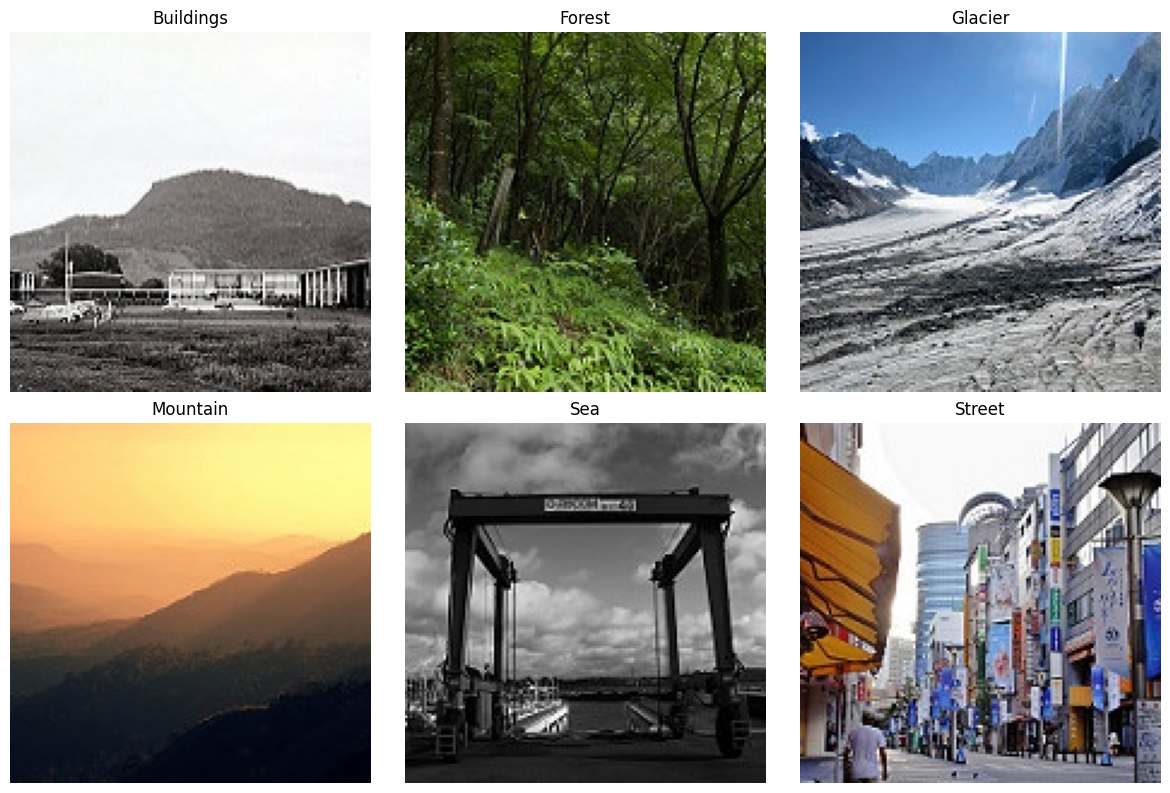

In [ ]:

# Display one sample image from each class
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for class_idx, class_name in enumerate(eda_dataset.classes):

    # Find the first image belonging to this class
    image_idx = next(
        i for i, (_, label) in enumerate(eda_dataset.samples)
        if label == class_idx
    )

    image, label = eda_dataset[image_idx]

    row = class_idx // 3
    col = class_idx % 3

    axes[row, col].imshow(image)
    axes[row, col].set_title(class_name.capitalize())
    axes[row, col].axis("off")

plt.tight_layout()
plt.show()


## 6.3 Inspect Image Dimensions and Color Channels

In [ ]:
from PIL import Image
from collections import Counter

# Inspect image dimensions and color modes
image_sizes = Counter()
image_modes = Counter()

for image_path, label in eda_dataset.samples:
    with Image.open(image_path) as img:
        image_sizes[img.size] += 1
        image_modes[img.mode] += 1

print("Most common image dimensions:")
for size, count in image_sizes.most_common(10):
    print(f"{size}: {count} images")

print("\nImage color modes:")
for mode, count in image_modes.items():
    print(f"{mode}: {count} images")

Most common image dimensions:
(150, 150): 13986 images
(150, 113): 7 images
(150, 135): 3 images
(150, 111): 3 images
(150, 108): 2 images
(150, 136): 2 images
(150, 143): 2 images
(150, 146): 2 images
(150, 134): 2 images
(150, 142): 2 images

Image color modes:
RGB: 14034 images


## 6.4 Analyze Class Distribution

Class Distribution:
buildings: 2191 images (15.61%)
forest: 2271 images (16.18%)
glacier: 2404 images (17.13%)
mountain: 2512 images (17.90%)
sea: 2274 images (16.20%)
street: 2382 images (16.97%)


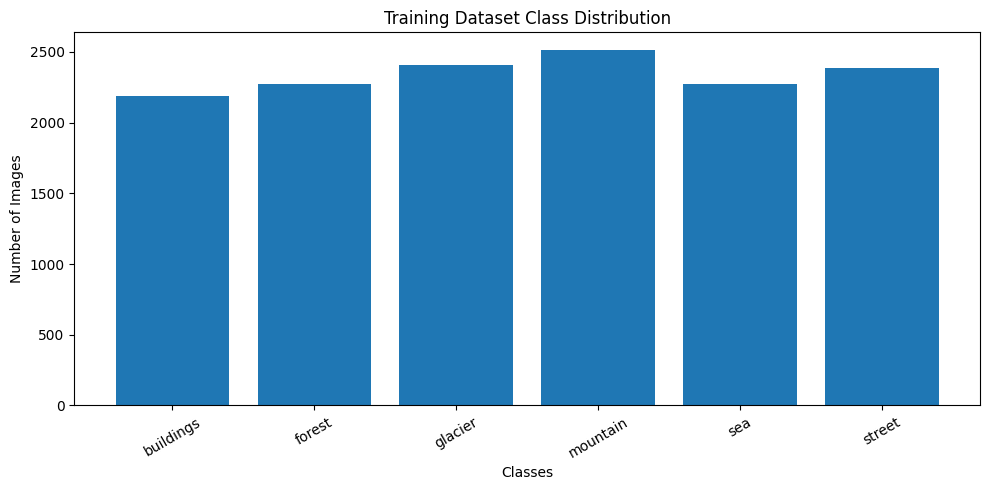

In [ ]:
# Count images in each class
class_counts = Counter(eda_dataset.targets)

class_names = eda_dataset.classes

counts = [
    class_counts[i] for i in range(len(class_names))
]

# Print class distribution
print("Class Distribution:")

for name, count in zip(class_names, counts):
    percentage = (count / len(eda_dataset)) * 100

    print(
        f"{name}: {count} images ({percentage:.2f}%)"
    )

# Visualize class distribution
plt.figure(figsize=(10, 5))

plt.bar(class_names, counts)

plt.title("Training Dataset Class Distribution")
plt.xlabel("Classes")
plt.ylabel("Number of Images")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# 7. DATA PREPROCESSING
## 7.1 Split Training and Validation Data

In [ ]:

from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

# Get all image indices and their corresponding labels
indices = np.arange(len(eda_dataset))
labels = np.array(eda_dataset.targets)

# Perform stratified 80:20 split
train_indices, val_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print("Training samples:", len(train_indices))
print("Validation samples:", len(val_indices))
print("Total samples:", len(train_indices) + len(val_indices))

Training samples: 11227
Validation samples: 2807
Total samples: 14034


## 7.2 Calculate Dataset Mean and Standard Deviation

In [ ]:
# Temporary transformation for calculating dataset statistics
stats_transform = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.ToTensor()
])

# Load training images with the temporary transformation
stats_dataset = datasets.ImageFolder(
    root=str(train_dir),
    transform=stats_transform
)

# Select only the training subset
stats_subset = Subset(stats_dataset, train_indices)

stats_loader = DataLoader(
    stats_subset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

# Accumulate pixel statistics for each RGB channel
channel_sum = torch.zeros(3)
channel_sum_sq = torch.zeros(3)

for images, _ in stats_loader:
    channel_sum += images.sum(dim=[0, 2, 3])
    channel_sum_sq += (images ** 2).sum(dim=[0, 2, 3])

# Calculate mean and standard deviation
num_pixels = len(stats_subset) * 150 * 150

dataset_mean = channel_sum / num_pixels

dataset_std = torch.sqrt(
    (channel_sum_sq / num_pixels) - (dataset_mean ** 2)
)

print("Dataset Mean:", dataset_mean)
print("Dataset Standard Deviation:", dataset_std)


Dataset Mean: tensor([0.4302, 0.4574, 0.4536])
Dataset Standard Deviation: tensor([0.2694, 0.2680, 0.2985])


## 7.3 Define Image Transformation Pipelines

In [ ]:
# Normalization values calculated from training images
mean = [0.4302, 0.4574, 0.4536]
std = [0.2694, 0.2680, 0.2985]

# Training transformations
train_transform = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Validation and testing transformations
test_transform = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

print("Training transformations:")
print(train_transform)

print("\nValidation and testing transformations:")
print(test_transform)


Training transformations:
Compose(
    Resize(size=(150, 150), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=(0.9, 1.1), hue=None)
    ToTensor()
    Normalize(mean=[0.4302, 0.4574, 0.4536], std=[0.2694, 0.268, 0.2985])
)

Validation and testing transformations:
Compose(
    Resize(size=(150, 150), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.4302, 0.4574, 0.4536], std=[0.2694, 0.268, 0.2985])
)


## 7.4 Create Training, Validation and Testing Datasets

In [ ]:
# Create separate dataset objects with appropriate transformations

train_dataset_full = datasets.ImageFolder(
    root=str(train_dir),
    transform=train_transform
)

val_dataset_full = datasets.ImageFolder(
    root=str(train_dir),
    transform=test_transform
)

test_dataset = datasets.ImageFolder(
    root=str(test_dir),
    transform=test_transform
)

# Apply the previously created stratified indices
train_dataset = Subset(
    train_dataset_full,
    train_indices
)

val_dataset = Subset(
    val_dataset_full,
    val_indices
)

# Verify class mappings
print("Training classes:", train_dataset_full.classes)
print("Validation classes:", val_dataset_full.classes)
print("Testing classes:", test_dataset.classes)

print("\nDataset sizes:")
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Training classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Validation classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Testing classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

Dataset sizes:
Training: 11227
Validation: 2807
Testing: 3000


## Step 7.5: Create DataLoaders

In [ ]:
# Define batch size
BATCH_SIZE = 32

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


Training batches: 351
Validation batches: 88
Testing batches: 94


## 7.6 Verify DataLoader Output

In [ ]:
# Get one batch of training images
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)

print("Minimum pixel value:", images.min().item())
print("Maximum pixel value:", images.max().item())

print("Unique labels in batch:", torch.unique(labels))

# Check for invalid numerical values
print("Contains NaN:", torch.isnan(images).any().item())
print("Contains Inf:", torch.isinf(images).any().item())


Image batch shape: torch.Size([32, 3, 150, 150])
Label batch shape: torch.Size([32])
Image data type: torch.float32
Label data type: torch.int64
Minimum pixel value: -1.7067162990570068
Maximum pixel value: 2.1150705814361572
Unique labels in batch: tensor([0, 1, 2, 3, 4, 5])
Contains NaN: False
Contains Inf: False


# 8. CUSTOM CNN ARCHITECTURE
## 8.1 Define the CNN Model

In [ ]:

class CustomCNN(nn.Module):

    def __init__(self, num_classes=6):
        super(CustomCNN, self).__init__()

        # Convolutional Block 1
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        # Convolutional Block 2
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        # Convolutional Block 3
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        # Adaptive Average Pooling
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        # Fully Connected Classifier
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)

        x = self.global_pool(x)

        x = self.classifier(x)

        return x

## 8.2 Initialize the CNN Model

In [ ]:

# Create the CNN model
model = CustomCNN(num_classes=6)

# Move model to the selected device
model = model.to(device)

print("Model initialized successfully!")
print("Selected device:", device)
print("Model architecture:")
print(model)

Model initialized successfully!
Selected device: cuda
Model architecture:
CustomCNN(
  (block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (gl

##Step 8.4: Test the forward pass

In [ ]:
# Get one batch of real training images
images, labels = next(iter(train_loader))

# Move images to GPU
images = images.to(device)

# Run a forward pass
model.eval()

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Expected output shape:", (32, 6))
print("Forward pass successful:", outputs.shape == (32, 6))


Input shape: torch.Size([32, 3, 150, 150])
Output shape: torch.Size([32, 6])
Expected output shape: (32, 6)
Forward pass successful: True


##Step 8.5: Calculate model parameters

In [ ]:

# Count total parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

# Count trainable parameters
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters: 110,982
Trainable parameters: 110,982


## 9. Custom CNN Architecture Summary

The custom CNN consists of three convolutional blocks followed by a classification head.

| Layer | Configuration | Output Shape |
|---|---|---|
| Input | RGB image | 3 × 150 × 150 |
| Conv Block 1 | Conv2D (32), BatchNorm, ReLU, MaxPool | 32 × 75 × 75 |
| Conv Block 2 | Conv2D (64), BatchNorm, ReLU, MaxPool | 64 × 37 × 37 |
| Conv Block 3 | Conv2D (128), BatchNorm, ReLU, MaxPool | 128 × 18 × 18 |
| Global Average Pooling | AdaptiveAvgPool2D | 128 × 1 × 1 |
| Flatten | Flatten | 128 |
| Fully Connected | Linear (128 → 128), ReLU | 128 |
| Dropout | Dropout (0.5) | 128 |
| Output Layer | Linear (128 → 6) | 6 |

**Total Parameters:** 110,982

**Trainable Parameters:** 110,982

The model uses convolutional layers to extract image features, batch normalization to stabilize training, max pooling to reduce spatial dimensions, and dropout to help reduce overfitting. The final fully connected layer produces six class scores.

#Step 10: Configure the training process

In [ ]:
# Define the loss function
criterion = nn.CrossEntropyLoss()

# Define the optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Number of training epochs
EPOCHS = 15

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Learning rate: 0.001")
print("Number of epochs:", EPOCHS)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Learning rate: 0.001
Number of epochs: 15


#Step 11: Training and validation loop

In [ ]:

# Store training and validation metrics
train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

for epoch in range(EPOCHS):

    # -------------------------
    # Training phase
    # -------------------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model parameters
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / total
    epoch_train_accuracy = 100 * correct / total

    # -------------------------
    # Validation phase
    # -------------------------
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_val_loss = running_loss / total
    epoch_val_accuracy = 100 * correct / total

    # Store metrics
    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    train_accuracies.append(epoch_train_accuracy)
    val_accuracies.append(epoch_val_accuracy)

    # Display epoch results
    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} "
        f"Train Accuracy: {epoch_train_accuracy:.2f}% "
        f"Val Loss: {epoch_val_loss:.4f} "
        f"Val Accuracy: {epoch_val_accuracy:.2f}%"
    )

print("\nTraining completed!")

Epoch [1/15] Train Loss: 1.0393 Train Accuracy: 57.42% Val Loss: 0.8446 Val Accuracy: 67.55%
Epoch [2/15] Train Loss: 0.7886 Train Accuracy: 69.32% Val Loss: 0.6993 Val Accuracy: 73.00%
Epoch [3/15] Train Loss: 0.7198 Train Accuracy: 72.95% Val Loss: 0.7047 Val Accuracy: 72.32%
Epoch [4/15] Train Loss: 0.6855 Train Accuracy: 74.21% Val Loss: 0.6346 Val Accuracy: 75.42%
Epoch [5/15] Train Loss: 0.6506 Train Accuracy: 75.75% Val Loss: 0.6073 Val Accuracy: 76.84%
Epoch [6/15] Train Loss: 0.6245 Train Accuracy: 76.81% Val Loss: 0.5455 Val Accuracy: 80.44%
Epoch [7/15] Train Loss: 0.6119 Train Accuracy: 77.35% Val Loss: 0.5739 Val Accuracy: 76.84%
Epoch [8/15] Train Loss: 0.5832 Train Accuracy: 78.12% Val Loss: 0.6669 Val Accuracy: 73.64%
Epoch [9/15] Train Loss: 0.5671 Train Accuracy: 79.04% Val Loss: 0.5114 Val Accuracy: 81.47%
Epoch [10/15] Train Loss: 0.5460 Train Accuracy: 79.91% Val Loss: 0.4926 Val Accuracy: 81.44%
Epoch [11/15] Train Loss: 0.5417 Train Accuracy: 80.54% Val Loss: 0.5

#Step 12: Plot training and validation curves

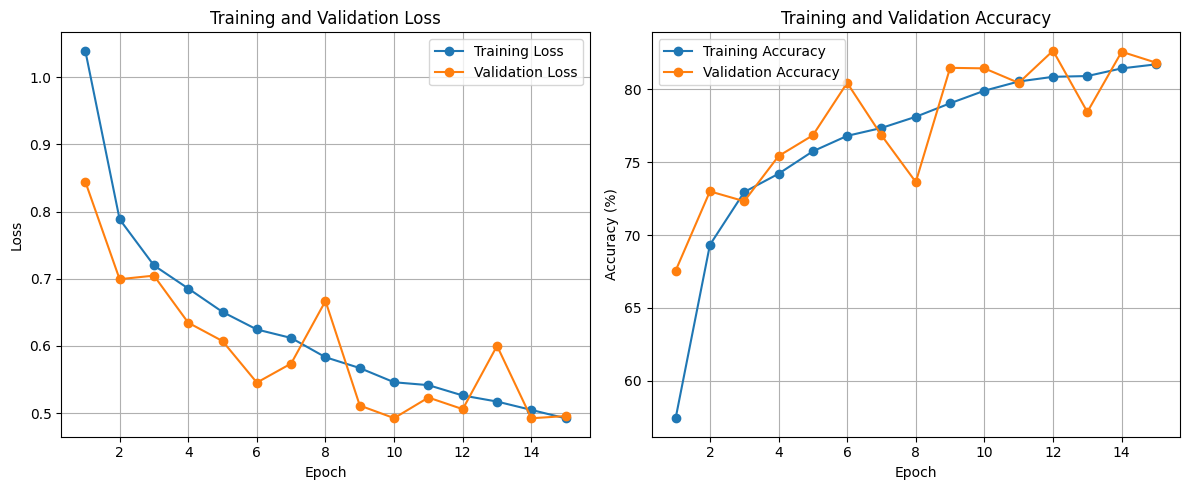

In [42]:
import matplotlib.pyplot as plt

epochs_range = range(1, EPOCHS + 1)

# Plot training and validation loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, marker='o', label='Training Loss')
plt.plot(epochs_range, val_losses, marker='o', label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot training and validation accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_accuracies, marker='o', label='Training Accuracy')
plt.plot(epochs_range, val_accuracies, marker='o', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### **Training and Validation Performance Analysis**

The training and validation curves demonstrate that the custom CNN successfully learned meaningful features from the Intel Natural Scenes dataset.

The training loss gradually decreased throughout the 15 epochs, indicating that the model improved its predictions during training. Validation loss also showed an overall decreasing trend, although some fluctuations occurred.

Training accuracy improved from **57.42% to 81.71%**, while validation accuracy reached a maximum of **82.65%** at epoch 12 and finished at **81.83%**.

The relatively small difference between training and validation accuracy suggests that the model generalizes reasonably well to unseen validation images. No significant overfitting is apparent from these results.

Overall, the model demonstrated stable learning and achieved promising classification performance across the six scene categories.

#Step 13: Evaluate on the test dataset

In [43]:

from sklearn.metrics import accuracy_score

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

# Calculate test accuracy
test_accuracy = accuracy_score(all_labels, all_predictions)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Total Test Images: {len(all_labels)}")

Test Accuracy: 82.93%
Total Test Images: 3000


### **Test Dataset Evaluation**

The trained CNN was evaluated on the independent test dataset containing 3,000 images.

The model achieved a test accuracy of **82.93%**, demonstrating that it can generalize to unseen images from the six scene categories.

This result is consistent with the validation performance and indicates that the model learned useful visual features during training.

#Step 14: Confusion matrix and classification report

##Generate the classification report

In [44]:
from sklearn.metrics import classification_report

class_names = test_dataset.classes

print("Classification Report:\n")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=class_names,
        digits=4
    )
)

Classification Report:

              precision    recall  f1-score   support

   buildings     0.8501    0.7529    0.7985       437
      forest     0.9014    0.9831    0.9405       474
     glacier     0.8479    0.7360    0.7880       553
    mountain     0.7953    0.7771    0.7861       525
         sea     0.7731    0.9020    0.8326       510
      street     0.8228    0.8343    0.8285       501

    accuracy                         0.8293      3000
   macro avg     0.8318    0.8309    0.8290      3000
weighted avg     0.8306    0.8293    0.8276      3000



##Generate the confusion matrix

<Figure size 900x700 with 0 Axes>

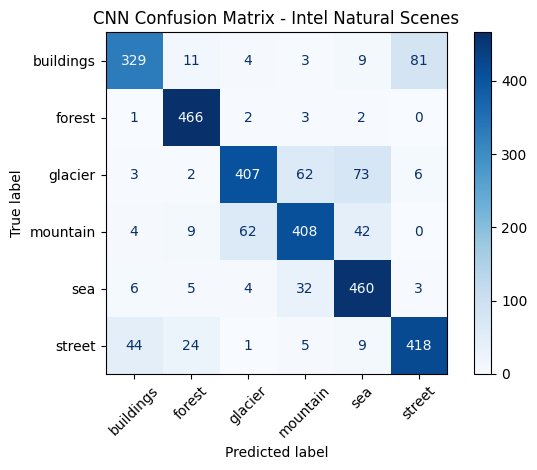

In [45]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title("CNN Confusion Matrix - Intel Natural Scenes")
plt.tight_layout()
plt.show()

### **Confusion Matrix and Classification Report Analysis**

The confusion matrix and classification report were used to evaluate the model's classification performance across all six scene categories.

The model achieved an overall test accuracy of **82.93%**, with a weighted F1-score of **82.76%.**

The forest category achieved the highest performance, with a precision of **90.14%**, recall of 98.31%, and F1-score of **94.05%**.

The glacier category was comparatively challenging, achieving a recall of **73.60%**. The confusion matrix indicates that glacier images were frequently misclassified as mountains and sea. Buildings and streets also showed some visual confusion.

These results suggest that the model learned useful visual patterns across all six categories, although certain visually similar scene classes remain challenging to distinguish.

Overall, the classification report and confusion matrix provide a more detailed understanding of the model's performance than accuracy alone.

#Step 15: Save your trained CNN model

In [46]:

# Save trained model checkpoint

checkpoint = {
    "model_state_dict": model.state_dict(),
    "class_names": test_dataset.classes,
    "num_classes": 6,
    "input_size": 150,
    "mean": mean,
    "std": std,
    "test_accuracy": test_accuracy,
    "epochs": EPOCHS
}

torch.save(checkpoint, "intel_custom_cnn.pth")

print("Model saved successfully!")
print("File: intel_custom_cnn.pth")

Model saved successfully!
File: intel_custom_cnn.pth


In [47]:
import os

model_path = "intel_custom_cnn.pth"

if os.path.exists(model_path):
    print("File exists:", model_path)
    print("File size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")
else:
    print("Model file not found!")

File exists: intel_custom_cnn.pth
File size: 0.43 MB


#Step 16: Load and verify the saved model

##Load the checkpoint

In [48]:

# Load the saved checkpoint
checkpoint = torch.load(
    "intel_custom_cnn.pth",
    map_location=device,
    weights_only=True
)

# Create a fresh model
loaded_model = CustomCNN(num_classes=6).to(device)

# Load saved weights
loaded_model.load_state_dict(checkpoint["model_state_dict"])

# Set evaluation mode
loaded_model.eval()

print("Checkpoint loaded successfully!")
print("Class names:", checkpoint["class_names"])
print("Saved test accuracy:", checkpoint["test_accuracy"] * 100, "%")

Checkpoint loaded successfully!
Class names: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Saved test accuracy: 82.93333333333334 %


##Verify predictions using the loaded model

In [49]:
loaded_predictions = []
loaded_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = loaded_model(images)

        _, predicted = torch.max(outputs, 1)

        loaded_predictions.extend(predicted.cpu().numpy())
        loaded_labels.extend(labels.numpy())

loaded_accuracy = accuracy_score(
    loaded_labels,
    loaded_predictions
)

print(f"Loaded Model Test Accuracy: {loaded_accuracy * 100:.2f}%")

print(
    "Accuracy matches original:",
    abs(loaded_accuracy - test_accuracy) < 1e-9
)

Loaded Model Test Accuracy: 82.93%
Accuracy matches original: True


### **Model Saving and Loading Verification**

The trained CNN model was saved in PyTorch `.pth` format using its state dictionary. The checkpoint also stores the class names, input image size, normalization parameters, number of epochs, and test accuracy.

To verify the saved model, a new instance of the CNN architecture was created and the saved weights were loaded into it.

The loaded model was evaluated again on the test dataset and achieved the same test accuracy of **82.93%**.

This confirms that the trained model was successfully saved, restored, and reused without losing its learned parameters.